In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from ISLP import load_data
from ISLP.models import (ModelSpec as MS, summarize)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from ISLP.models import sklearn_sm
from sklearn.model_selection import \
 (cross_validate,
 KFold,
 ShuffleSplit)

In [43]:
rng = np.random.default_rng(2)
x = rng.normal(size=100)
y = x- 2 * x**2 + rng.normal(size=100)

n = 100 observations, p = 1, y = x - 2x^2 + error term

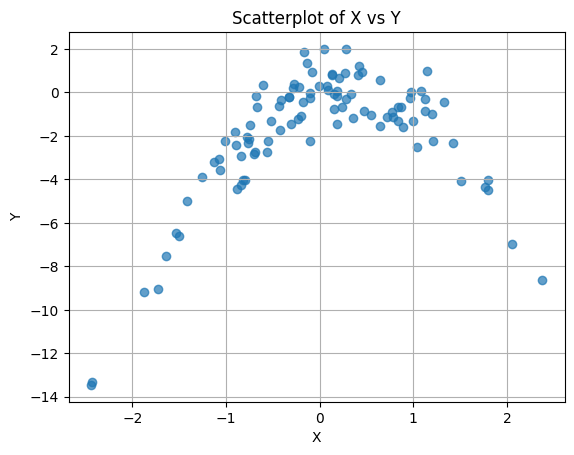

In [44]:
plt.scatter(x, y, alpha=0.7)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Scatterplot of X vs Y")
plt.grid(True)

In [45]:
df = pd.DataFrame({'x': x, 'y': y})
X = df[['x']].values
Y = df['y'].values

In [46]:
cv_error = np.zeros(4)
H = np.array(df['x'])
M = sklearn_sm(sm.OLS)
for i, d in enumerate(range(1,5)):
    X = np.power.outer(H, np.arange(d+1))
    M_CV = cross_validate(M, X, Y, cv=df.shape[0])
    cv_error[i] = np.mean(M_CV['test_score'])
cv_error

array([7.56060369, 0.98403717, 0.96823558, 0.96595856])

In [35]:
#result from c is array([6.63302984, 1.12293686, 1.30179655, 1.33239427]), above code now different seed (original seed = 1)

In [34]:
#result for d is array([7.56060369, 0.98403717, 0.96823558, 0.96595856]), different possibly because of error term though same 
#conclusion can be reached, which is that a quadratic model fits best. This is less apparent now which shows LOOCV can be fickle
#since individual observations may be outliers and that one may reach false conclusions from LOOCV

In [47]:
H = np.array(df['x'])

for d in range(1, 5):
    # Construct polynomial features
    X = np.power.outer(H, np.arange(d+1))
    X_with_intercept = sm.add_constant(X)  # Adds intercept term
    model = sm.OLS(Y, X_with_intercept).fit()
    print(f"\n--- Polynomial Degree {d} ---")
    print(model.summary())


--- Polynomial Degree 1 ---
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.156
Model:                            OLS   Adj. R-squared:                  0.148
Method:                 Least Squares   F-statistic:                     18.15
Date:                Fri, 25 Jul 2025   Prob (F-statistic):           4.68e-05
Time:                        20:34:46   Log-Likelihood:                -238.27
No. Observations:                 100   AIC:                             480.5
Df Residuals:                      98   BIC:                             485.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.8158  

In [48]:
#This directly supports our conclusion which is that the quadratic model is the superior fit.